<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/pinn_pendulum_period.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Discovering the period of a pendulum dropped from $\theta_0=150^{\circ}$ via a 2 hidden layer PINN.

 Starting Zero-Data PINN: 150-Degree Pendulum Drop


/tmp/ipykernel_624/1534221070.py:115: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Iteration  500 | Loss: 3.368055
Iteration 1000 | Loss: 0.011430
Iteration 1500 | Loss: 0.001028
Iteration 2000 | Loss: 0.000429
Iteration 2500 | Loss: 0.000201
Iteration 3000 | Loss: 0.000116

Training Complete in 15.61s!
Final Loss: 0.000114

 Small-Angle Formula Period: 2.007 seconds
 True Mathematical Period:   3.537 seconds
 PINN Discovered Period:     3.535 seconds


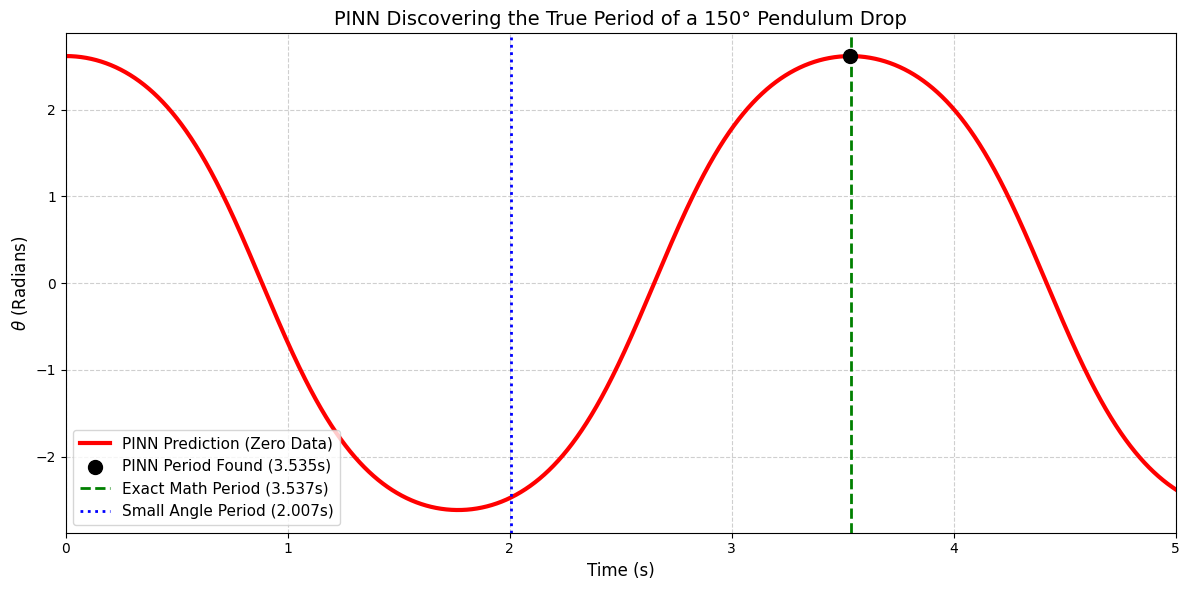

In [1]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad

# Force JAX to use 64-bit precision to match SciPy and prevent crashes!
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp
import time

def unpack_weights(params, H):
    """Reconstructs the weight matrices from the flat 1D array."""
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H*H].reshape(H, H); idx += H*H
    b2 = params[idx : idx+H].reshape(1, H); idx += H
    W3 = params[idx : idx+H].reshape(H, 1); idx += H
    b3 = params[idx : idx+1].reshape(1, 1)
    return W1, b1, W2, b2, W3, b3

def pack_weights(W1, b1, W2, b2, W3, b3):
    """Flattens weights into a 1D array for the SciPy optimizer."""
    return np.concatenate([
        W1.flatten(), b1.flatten(),
        W2.flatten(), b2.flatten(),
        W3.flatten(), b3.flatten()
    ])

def forward_with_physics(params, t, H):
    """
    Calculates position, velocity, and acceleration analytically for a 2-layer network.
    """
    W1, b1, W2, b2, W3, b3 = unpack_weights(params, H)

    # Scale time (0 to 5 seconds mapped to 0 to 1)
    t_max = 5.0
    tau = t / t_max
    dtau_dt = 1.0 / t_max

    # 1. Feed-Forward
    a1 = jnp.tanh(jnp.dot(tau, W1) + b1)
    a2 = jnp.tanh(jnp.dot(a1, W2) + b2)
    theta = jnp.dot(a2, W3) + b3

    # 2. Velocity (Chain Rule)
    da1_dtau = (1 - a1**2) * W1
    dz2_dtau = jnp.dot(da1_dtau, W2)
    da2_dtau = (1 - a2**2) * dz2_dtau
    velocity = jnp.dot(da2_dtau, W3) * dtau_dt

    # 3. Acceleration (Product Rule + Chain Rule)
    d2a1_dtau2 = -2 * a1 * (1 - a1**2) * (W1**2)
    d2z2_dtau2 = jnp.dot(d2a1_dtau2, W2)
    d2a2_dtau2 = -2 * a2 * da2_dtau * dz2_dtau + (1 - a2**2) * d2z2_dtau2
    acceleration = jnp.dot(d2a2_dtau2, W3) * (dtau_dt**2)

    return theta, velocity, acceleration

def compute_loss(params, t_domain, t_ic, theta_0, omega_0, H):
    """Calculates the total error across the 5-second domain."""
    # Physics Loss (ODE: theta'' + 9.8 * sin(theta) = 0)
    theta, _, acceleration = forward_with_physics(params, t_domain, H)
    residual = acceleration + 9.8 * jnp.sin(theta)
    loss_ode = jnp.mean(residual**2)

    # Initial Condition Loss (t=0)
    theta_pred_ic, velocity_pred_ic, _ = forward_with_physics(params, t_ic, H)
    loss_ic_position = jnp.mean((theta_pred_ic - theta_0)**2)
    loss_ic_velocity = jnp.mean((velocity_pred_ic - omega_0)**2)

    return loss_ode + loss_ic_position + loss_ic_velocity

# JIT Compile the Loss and Gradients
loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(5,))

def scipy_objective(params, t_domain, t_ic, theta_0, omega_0, H):
    loss, grads = loss_and_grad(params, t_domain, t_ic, theta_0, omega_0, H)
    return float(loss), np.array(grads)

H = 32
t_domain = jnp.linspace(0, 5, 400).reshape(-1, 1) # 400 collocation points
t_ic = jnp.array([[0.0]])

# 150 degrees in radians
theta_0 = 150.0 * (np.pi / 180.0)
omega_0 = 0.0

np.random.seed(42)
W1 = np.random.randn(1, H) * 10.0 # Scaling to break spectral bias!
b1 = np.zeros((1, H))
W2 = np.random.randn(H, H) * np.sqrt(2.0 / (H + H))
b2 = np.zeros((1, H))
W3 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b3 = np.zeros((1, 1))

initial_weights = pack_weights(W1, b1, W2, b2, W3, b3)

progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    if progress['iterations'] % 500 == 0:
        current_loss = compute_loss(xk, t_domain, t_ic, theta_0, omega_0, H)
        print(f"Iteration {progress['iterations']:4d} | Loss: {float(current_loss):.6f}")

print("==================================================")
print(" Starting Zero-Data PINN: 150-Degree Pendulum Drop")
print("==================================================")
start_time = time.time()

res = minimize(
    fun=scipy_objective,
    x0=initial_weights,
    args=(t_domain, t_ic, theta_0, omega_0, H),
    method='L-BFGS-B',
    jac=True,
    callback=monitor_progress,
    options={'maxiter': 5000, 'maxfun': 50000, 'disp': False}
)

final_weights = res.x
elapsed = time.time() - start_time
print(f"\nTraining Complete in {elapsed:.2f}s!")
print(f"Final Loss: {res.fun:.6f}")

# Evaluate on a highly dense time grid to precisely find zero-crossings
t_eval = np.linspace(0, 5, 5000).reshape(-1, 1)
theta_pred, vel_pred, _ = forward_with_physics(final_weights, t_eval, H)

vel_pred = np.array(vel_pred).flatten()
t_eval_flat = t_eval.flatten()

# Find where velocity crosses zero (sign changes)
sign_changes = np.where(np.diff(np.sign(vel_pred)))[0]

# Filter out the initial drop at t=0.
# A full swing happens when velocity hits 0 for the SECOND time after the drop.
valid_crossings = [t_eval_flat[idx] for idx in sign_changes if t_eval_flat[idx] > 0.5]
pinn_period = valid_crossings[1] if len(valid_crossings) >= 2 else None

# Exact Analytical Period using the Complete Elliptic Integral of the First Kind
k = np.sin(theta_0 / 2.0)
m = k**2
exact_period = 4.0 * (1.0 / np.sqrt(9.8)) * sp.ellipk(m)

# Small Angle Approximation Period
small_angle_period = 2.0 * np.pi * np.sqrt(1.0 / 9.8)

print("\n==================================================")
print(f" Small-Angle Formula Period: {small_angle_period:.3f} seconds")
print(f" True Mathematical Period:   {exact_period:.3f} seconds")
print(f" PINN Discovered Period:     {pinn_period:.3f} seconds")
print("==================================================")

plt.figure(figsize=(12, 6))

plt.plot(t_eval_flat, theta_pred, 'r-', linewidth=3, label='PINN Prediction (Zero Data)')

# Mark the discovered period
if pinn_period:
    plt.scatter([pinn_period], [theta_0], color='black', s=100, zorder=5,
                label=f'PINN Period Found ({pinn_period:.3f}s)')

# Draw vertical lines for comparison
plt.axvline(x=exact_period, color='green', linestyle='--', linewidth=2,
            label=f'Exact Math Period ({exact_period:.3f}s)')
plt.axvline(x=small_angle_period, color='blue', linestyle=':', linewidth=2,
            label=f'Small Angle Period ({small_angle_period:.3f}s)')

plt.title("PINN Discovering the True Period of a 150° Pendulum Drop", fontsize=14)
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("$\\theta$ (Radians)", fontsize=12)
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(0, 5)
plt.tight_layout()
plt.show()